# Road Surface Type Classification Task

### [GitHub Link](https://github.com/anthonyandrei/csc930m-project)

## Phase 1

### Section 1: List of requirements

This section records the software environment and package versions needed to reproduce the dataset audit, exploratory analysis, and model experiments on the JupyterHub VM. NumPy and pandas handle arrays and tables, Pillow handles images, scikit-learn supplies evaluation metrics, and PyTorch searches for nearest neighbors and trains the neural network on a GPU.

In [1]:
import sys
from pathlib import Path
import pandas as pd

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.helper.inventory import get_environment_info

env_info = get_environment_info()
env_rows = [("Python", env_info["python_version"]), ("Platform", env_info["os"])]
env_rows.extend(env_info["packages"].items())
pd.DataFrame(env_rows, columns=["Component", "Version"])

,Component,Version
0,Python,3.12.6
1,Platform,Linux 5.15.0-202-generic
2,numpy,2.3.5
3,pandas,3.0.6
4,opencv-python,not installed
5,pillow,12.3.0
6,scikit-learn,1.9.1
7,torch,2.14.0+cu126


### Section 2: Description of the dataset

Our primary objective is five-class road surface type classification. The model predicts the ground surface material visible in an input image: asphalt, concrete, paving stones, sett, or unpaved. A secondary attribute present in the dataset is surface quality, recorded across five condition levels from very bad to excellent. For our project scope, surface quality is retained purely as descriptive metadata and is excluded from the prediction targets.

The project uses StreetSurfaceVis v1.0, published on [Zenodo](https://doi.org/10.5281/zenodo.11449977) (Kapp et al., 2024). The authors collected street-level imagery in Germany through Mapillary. The release offers several image sizes based on width, not the shorter side. We use the s_256 release; most files are 256 pixels wide, with varying heights.

Metadata is provided in streetSurfaceVis_v1_0.csv, which documents nine columns: mapillary_image_id, user_id, user_name, captured_at, longitude, latitude, train, surface_type, and surface_quality. Each image file in s_256 is named after its unique ID with a .jpg extension. This establishes a 1-to-1 deterministic mapping between metadata rows and image files.

Crowdsourced images were captured by volunteer drivers, cyclists, and pedestrians using mobile devices. Consequently, the dataset exhibits substantial variability in camera pitch, mounting height, weather, and seasonal illumination. Coverage is confined to Germany. This geographic focus concentrates regional roadway patterns, such as cobblestone sett and interlocking pavers.

The images vary within each surface type and include background clutter from vehicles, roadside structures, and vegetation. The official release contains 9,122 records (Kapp et al., 2025). We check for corrupt or missing files before splitting the data.

In [2]:
import os

BASE_DATA = ROOT_DIR / "data"
METADATA_PATH = str(BASE_DATA / "streetSurfaceVis_v1_0.csv")
DATA_PATH = str(BASE_DATA / "s_256")

### Section 3: Exploratory data analysis

We check every CSV record for repeated image IDs and fully repeated rows. These counts describe different problems: an ID can recur even if its other fields differ.


In [3]:
from src.helper.inventory import load_and_validate_metadata

metadata_df, metadata_summary = load_and_validate_metadata(METADATA_PATH)
pd.DataFrame([metadata_summary]).T.rename(columns={0: "Value"})

,Value
total_records,9122
expected_total,9122
train_records,8346
expected_train,8346
test_records,776
expected_test,776
unique_ids,9122
duplicate_ids,0
fully_repeated_rows,0
has_nulls,False


We check whether each named image file exists and can be opened. Only readable files enter the byte comparison below.


In [4]:
from src.helper.inventory import audit_image_inventory

inventory_df, audit_summary, missing_ids, decode_fails, extra_files = (
    audit_image_inventory(metadata_df, DATA_PATH)
)
pd.DataFrame([audit_summary]).T.rename(columns={0: "Count"})

,Count
expected_images,9122
found_images,9122
readable_images,9120
missing_images,0
decode_failures,2
extra_files,0
unusable_images,2


We compare the bytes of all 9,120 readable files. Matching SHA-256 digests are confirmed byte for byte. Group counts show where identical images occur in the published partitions; copies still count as separate usable records in the EDA.


In [5]:
from src.helper.inventory import audit_duplicate_images

duplicate_summary, duplicate_groups, read_failures = audit_duplicate_images(inventory_df)
assert duplicate_summary["compared_files"] + duplicate_summary["read_failures"] == inventory_df.loc[inventory_df["is_readable"], "file_path"].nunique()
pd.DataFrame([duplicate_summary]).T.rename(columns={0: "Count"})


,Count
compared_files,9120
read_failures,0
identical_file_groups,8
affected_image_ids,16
within_train_groups,8
within_test_groups,0
cross_split_groups,0
conflicting_surface_type_groups,0
conflicting_surface_quality_groups,1


The release has 9,122 unique image IDs and no repeated CSV rows. Of these, 9,120 images are readable; two training files are empty, with none missing or extra. Eight byte-identical pairs involve 16 IDs, all in published training, with no exact duplicates crossing into test. Every pair agrees on surface type.

#### Surface-type balance

The table compares published release records with readable images. Each percentage uses the readable total for its own partition.

In [6]:
partitions = {
    "all": inventory_df,
    "train": inventory_df.loc[inventory_df["train"]],
    "test": inventory_df.loc[~inventory_df["train"]],
}
balance_rows = []
for partition, records in partitions.items():
    usable_total = int(records["is_readable"].sum())
    for surface_type, group in records.groupby("surface_type", sort=True):
        usable_count = int(group["is_readable"].sum())
        balance_rows.append({
            "partition": partition, "surface_type": surface_type,
            "release records": len(group), "usable images": usable_count,
            "usable %": round(100 * usable_count / usable_total, 1),
        })
balance = pd.DataFrame(balance_rows)
assert balance.groupby("partition")["usable images"].sum().to_dict() == {"all": 9120, "train": 8344, "test": 776}
balance

,partition,surface_type,release records,usable images,usable %
0,all,asphalt,3734,3734,40.9
1,all,concrete,972,971,10.6
2,all,paving_stones,2037,2037,22.3
3,all,sett,1363,1362,14.9
4,all,unpaved,1016,1016,11.1
5,train,asphalt,3204,3204,38.4
6,train,concrete,956,955,11.4
7,train,paving_stones,1924,1924,23.1
8,train,sett,1331,1330,15.9
9,train,unpaved,931,931,11.2


Asphalt is the largest class: 3,734 of 9,120 usable images (40.9%). Concrete has 971 (10.6%). The published test set has 16 concrete and 32 sett images. The two unreadable records account for the release-to-usable differences.

#### Training examples

The next figure uses two fixed, readable training IDs for each surface type. The published labels stay as given. These ten images illustrate possible confusion.


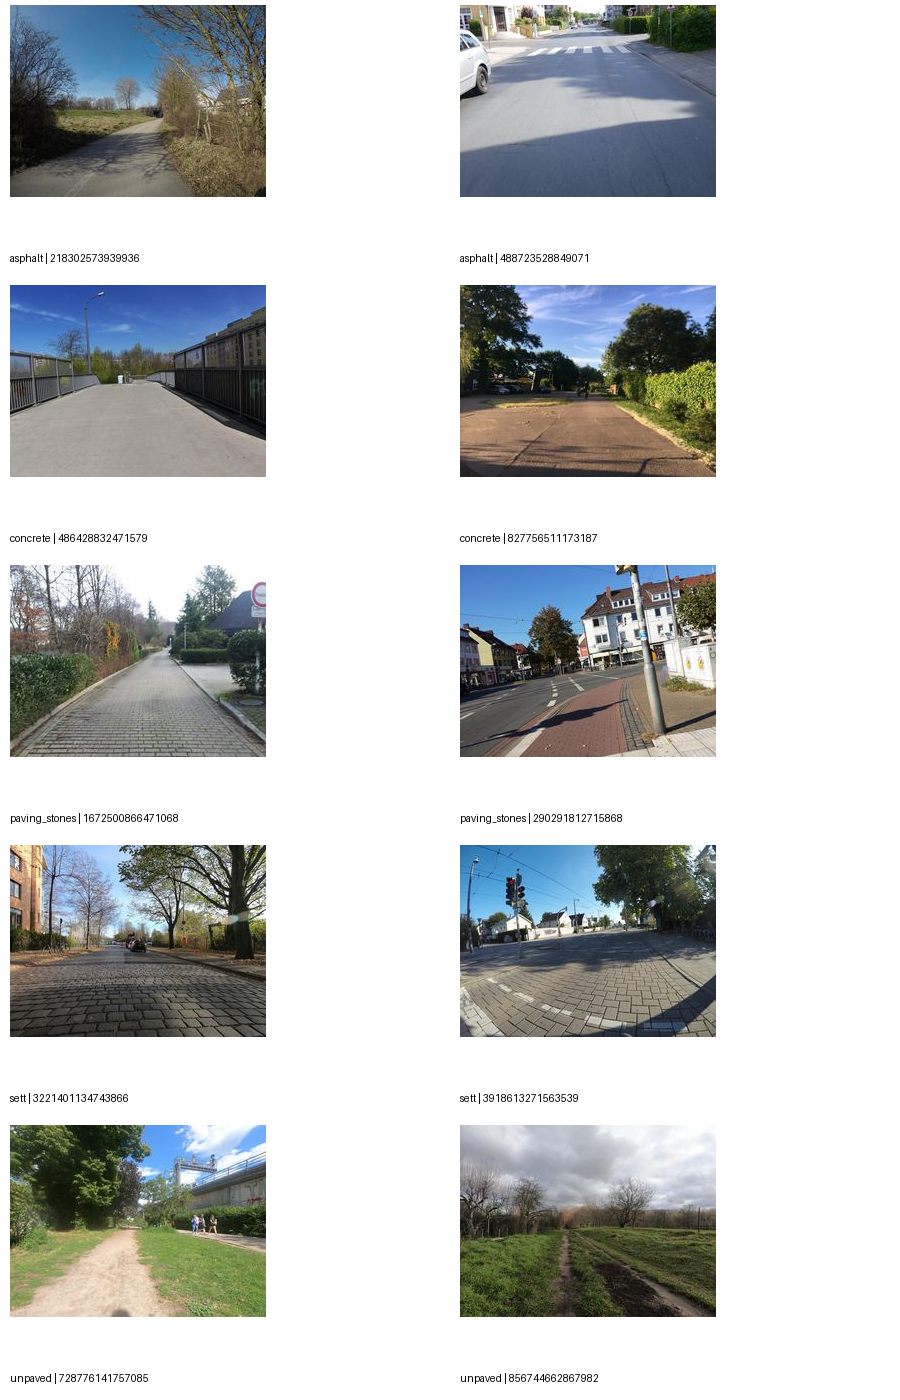

In [7]:
from PIL import Image
from IPython.display import display
from src.helper.figures import training_examples_figure

example_ids = {
    "asphalt": ["218302573939936", "488723528849071"],
    "concrete": ["486428832471579", "827756511173187"],
    "paving_stones": ["1672500866471068", "290291812715868"],
    "sett": ["3221401134743866", "3918613271563539"],
    "unpaved": ["728776141757085", "856744662867982"],
}
display(training_examples_figure(inventory_df, example_ids))

The smooth asphalt example can resemble the smooth concrete example. Paving stones and sett both show repeated blocks; the chosen sett example with square blocks is especially easy to confuse with paving stones. The unpaved examples range from a dry path to a muddy track.

#### Image dimensions

We record each readable image's width and height. The table shows the two most common sizes and sizes containing the smallest or largest width or height.

In [8]:
usable_images = inventory_df.loc[inventory_df["is_readable"]].copy()
dimensions = []
for image_path in usable_images["file_path"]:
    with Image.open(image_path) as image:
        dimensions.append(image.size)
usable_images[["width", "height"]] = dimensions
assert len(usable_images) == len(dimensions) == 9120
sizes = usable_images.groupby(["width", "height"]).size().reset_index(name="images")
common_sizes = sizes.nlargest(2, "images").assign(summary="common size")
extreme_indices = sizes[["width", "height"]].agg(["idxmin", "idxmax"]).to_numpy().ravel()
extreme_sizes = sizes.loc[extreme_indices].assign(summary="dimension extreme")
pd.concat([common_sizes, extreme_sizes]).drop_duplicates(["width", "height"])[
    ["summary", "width", "height", "images"]
]

,summary,width,height,images
43,common size,256,192,6644
36,common size,256,144,1754
0,dimension extreme,81,144,2
28,dimension extreme,256,110,1
52,dimension extreme,256,458,5


Most files are 256 pixels wide. The common sizes are 256 × 192 (6,644 images) and 256 × 144 (1,754 images); a few have unusual proportions. We use a 128 × 96 canvas to keep the shared pixel vector manageable. Section 5 crops the lower-center road region, preserves its aspect ratio, and pads it to this canvas.

### Section 4: Dataset split

We preserve the published test assignment and divide the remaining images into training and validation sets. The exclusions are two unreadable images and the two images in the duplicate pair with conflicting surface-quality labels. This leaves 9,118 included records. Groups 1 to 7 retain both copies within the same split.

The next cell filters the inventory, generates the splits, verifies them, and saves the assignments to `data/splits.csv`. It uses seed 42 and a 0.78 training share of the 8,342 included records in published training. The remaining 22% goes to validation by surface type, keeping duplicate groups together. The result is 6,507 training, 1,835 validation, and 776 test images: 71.36%, 20.13%, and 8.51% overall. This approximates the intended 70/20/10 allocation while preserving the published test set.

In [9]:
from src.helper.dataset_split import (
    filter_usable_dataset,
    generate_dataset_splits,
    verify_dataset_splits,
    save_split_assignments,
)

usable_df, exclusions = filter_usable_dataset(inventory_df, duplicate_groups)
split_df = generate_dataset_splits(
    usable_df=usable_df,
    duplicate_groups=duplicate_groups,
    train_val_ratio=0.78,
    random_state=42,
)
verification = verify_dataset_splits(split_df, duplicate_groups)
splits_csv = save_split_assignments(split_df, str(BASE_DATA / "splits.csv"))

print(f"Usable: {len(usable_df):,} | Excluded: {exclusions['total_excluded']}")
print(f"Splits: {verification['split_counts']}")
print(f"Proportions (%): {verification['split_proportions_pct']}")
display(verification["type_distribution"])

Usable: 9,118 | Excluded: 4
Splits: {'train': 6507, 'val': 1835, 'test': 776}
Proportions (%): {'train': 71.36, 'val': 20.13, 'test': 8.51}


split,test,train,val,All
surface_type,,,,
asphalt,530,2499,705,3734
concrete,16,745,210,971
paving_stones,113,1501,423,2037
sett,32,1036,292,1360
unpaved,85,726,205,1016
All,776,6507,1835,9118


The verifier checks disjoint image IDs, preserved published test membership, exact-duplicate separation, and complete coverage. We save the verified assignments by image ID so every model uses the same split.

### Section 5: Traditional ML model training

#### Shared RGB inputs

The [StreetSurfaceVis Usage Notes](https://www.nature.com/articles/s41597-024-04295-9#Sec11) recommend cropping because annotations describe the road at the bottom center. We keep the central half of the width and bottom half of the height: crop bounds are `(0.25 × width, 0.50 × height, 0.75 × width, height)`.

Our crop fits inside a 128 × 96 black canvas without stretching. A 256 × 192 image yields a 128 × 96 crop. A 256 × 144 image yields a 128 × 72 crop with 12 black rows above and below.

The next figure shows two included training images beside their prepared versions, one for each common source size. Padding stays visible in the prepared image.

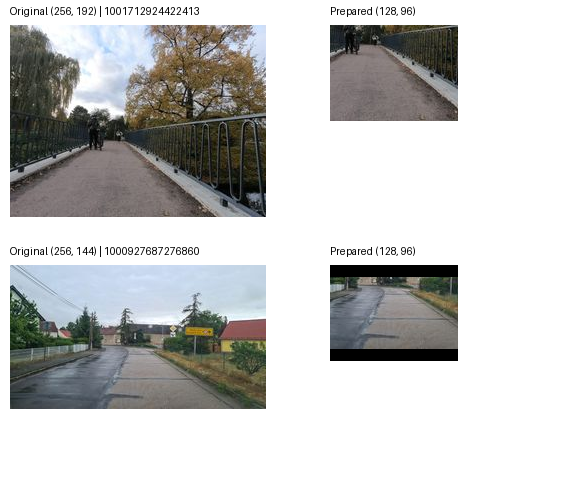

In [10]:
import numpy as np
from src.helper.shared_inputs import prepare_split, LABEL_IDS, SEED, evaluate_predictions
from src.helper.figures import crop_comparison_figure

comparison_sizes = [(256, 192), (256, 144)]
display(crop_comparison_figure(split_df, comparison_sizes))

Every prepared image has height 96, width 128, and three channels in red, green, blue (RGB) order. Dividing each 8-bit channel value by 255.0 gives float32 values from zero to one. Flattening reads rows left to right, yielding 36,864 features.

We prepare each saved split in row order, keeping image IDs and encoded surface-type labels beside the pixels. Checks confirm finite pixel values between zero and one. The table summarizes image, flattened-feature, and label shapes.

In [11]:
shared = {
    name: prepare_split(split_df.loc[split_df["split"] == name], DATA_PATH)
    for name in ("train", "val", "test")
}
feature_summary = []
for name, data in shared.items():
    assert np.isfinite(data["images"]).all()
    assert 0 <= data["images"].min() <= data["images"].max() <= 1
    feature_summary.append({"split": name, "images": data["images"].shape,
                            "flat": data["flat"].shape, "labels": data["labels"].shape})
pd.DataFrame(feature_summary)

,split,images,flat,labels
0,train,"(6507, 96, 128, 3)","(6507, 36864)","(6507,)"
1,val,"(1835, 96, 128, 3)","(1835, 36864)","(1835,)"
2,test,"(776, 96, 128, 3)","(776, 36864)","(776,)"


#### Selection and reporting protocol

All candidates use the same training and validation splits. We select the highest unrounded validation macro-F1, breaking ties by validation accuracy, then grid order. F1 combines precision (how often a predicted class is correct) and recall (how many actual examples of a class are found). Macro-F1 weights all five surface types equally. We show only the top five configurations and round scores for display. Training and validation scores help assess fit; the selected model, fitted on the original training split, is evaluated on the test set once.

Evaluation reports accuracy, macro-F1, and per-class precision, recall, F1, and support (sample count). Confusion-matrix rows are actual classes and columns are predictions. The class order is asphalt, concrete, paving_stones, sett, and unpaved, encoded 0 through 4. Undefined scores are zero.

#### k-nearest neighbors baseline

For each image, k-nearest neighbors (kNN) finds the k closest training images and predicts their most common surface type. We choose this baseline to compare stored-image similarity with the neural network's learned weights. Both use the shared normalized RGB pixels. kNN uses Euclidean distance (straight-line distance between pixel vectors), exact brute-force search, and one vote per neighbor. PyTorch searches in batches on one GPU, which stores the training pixels. kNN has no gradient training, optimizer, learning rate, or epochs.

We evaluate every integer k from 1 through 20, following the range examined by [Marianingsih et al. (2022)](https://doi.org/10.17977/um016v6i12022p040) on a different road-image dataset. The helper retrieves 20 neighbors per validation image once and reuses their labels for all candidates. Tied votes select the lowest class ID; tied distances can change neighbor order. Before tuning, we check that prepared image IDs and labels match the saved split assignments.

In [12]:
import torch
from src.helper.knn import K_VALUES, tune_knn

torch.set_float32_matmul_precision("highest")
saved_assignments = pd.read_csv(BASE_DATA / "splits.csv", dtype={"mapillary_image_id": str})
for name, data in shared.items():
    assigned = saved_assignments.loc[saved_assignments["split"] == name]
    np.testing.assert_array_equal(data["image_ids"], assigned["mapillary_image_id"])
    np.testing.assert_array_equal(data["labels"], assigned["surface_type"].map(LABEL_IDS))

We score all 20 k values on validation data and display the top five configurations. The selected model retains only the original training images as its reference set.

In [13]:
knn_search = tune_knn(
    train_features=shared["train"]["flat"],
    train_labels=shared["train"]["labels"],
    validation_features=shared["val"]["flat"],
    validation_labels=shared["val"]["labels"],
    device=os.environ.get("KNN_DEVICE", "cuda:2"),
)
assert len(knn_search["candidates"]) == len(K_VALUES)

knn_model = knn_search["model"]
knn_selected = knn_search["top_five"][0]

score_columns = ["k", "validation_macro_f1", "validation_accuracy"]
knn_top_five = pd.DataFrame(knn_search["top_five"], columns=score_columns)
display(knn_top_five.round(4))

print(f"Selected k: {knn_selected['k']}")
print(f"Original training rows: {knn_model.n_samples_fit_}")

,k,validation_macro_f1,validation_accuracy
0,1,0.2950,0.3717
1,3,0.2665,0.3962
2,9,0.2595,0.4109
3,4,0.2582,0.3853
4,5,0.2551,0.3886


Selected k: 1
Original training rows: 6507


The search selected k = 1, with validation macro-F1 0.2950 and accuracy 37.17%. The fitted reference set contains the original 6,507 training images.

We query the training images and reuse the selected validation predictions. The table compares accuracy and macro-F1 on both splits to assess fit.

In [14]:
knn_train_predictions = knn_model.predict(shared["train"]["flat"])
knn_train_report = evaluate_predictions(shared["train"]["labels"], knn_train_predictions)
knn_validation_report = evaluate_predictions(
    shared["val"]["labels"], knn_selected["predictions"]
)
knn_fit_scores = pd.DataFrame({
    name: {metric: report[metric] for metric in ("accuracy", "macro_f1")}
    for name, report in (("training", knn_train_report), ("validation", knn_validation_report))
}).T
display(knn_fit_scores.round(4))

,accuracy,macro_f1
training,1.0000,1.000
validation,0.3717,0.295


At k = 1, training accuracy and macro-F1 were both 1.0000, while validation accuracy was 0.3717 and macro-F1 was 0.2950. Training exceeded validation by 62.83 percentage points in accuracy and 0.7050 in macro-F1. Each training image can retrieve itself as its nearest neighbor, explaining the perfect training score. The much lower validation scores show poor performance on unseen images.

We evaluate the selected k on the test set once. The reports show overall accuracy and macro-F1, per-class scores, and a confusion matrix to interpret performance across the imbalanced classes.

In [15]:
assert knn_model.n_samples_fit_ == len(shared["train"]["labels"])
knn_test_predictions = knn_model.predict(shared["test"]["flat"])
knn_test_report = evaluate_predictions(shared["test"]["labels"], knn_test_predictions)
display(pd.Series({metric: knn_test_report[metric] for metric in ("accuracy", "macro_f1")},
                  name="test score").round(4).to_frame())
display(knn_test_report["per_class"].round(4))
display(knn_test_report["confusion_matrix"])
assert knn_test_report["per_class"].loc["concrete", "support"] == 16

,test score
accuracy,0.4394
macro_f1,0.2360


,precision,recall,f1,support
asphalt,0.7759,0.5226,0.6246,530
concrete,0.0233,0.1250,0.0392,16
paving_stones,0.1955,0.3805,0.2583,113
sett,0.0238,0.0312,0.0270,32
unpaved,0.2535,0.2118,0.2308,85


predicted,asphalt,concrete,paving_stones,sett,unpaved
actual,,,,,
asphalt,277,50,135,28,40
concrete,4,2,7,2,1
paving_stones,41,18,43,4,7
sett,10,2,14,1,5
unpaved,25,14,21,7,18


Test accuracy was 43.94%, while macro-F1 was 0.2360. Asphalt had the highest F1 (0.6246) and accounted for 530 of 776 test images. Every other class had F1 at or below 0.2583. The higher accuracy therefore masks weak performance across the smaller classes.

#### Neural-network experiments

The feedforward neural network provides a parametric baseline consuming the same 36,864 normalized pixel values per image as kNN. Each hidden layer computes linear combinations using learned weights and biases, followed by a rectified linear unit (ReLU) activation. The output layer maps hidden activations to five class logits evaluated through Softmax and categorical cross-entropy loss. Standard mini-batch stochastic gradient descent (SGD), without momentum, iteratively updates the parameter matrices across twenty training epochs.

We try every combination of network depth (1 to 5 hidden layers, matching class count), hidden neuron width (32, 64, 128 neurons per layer), and learning rate (0.01, 0.03, 0.05). This produces 45 candidate configurations. Each candidate trains for 20 epochs (passes through the training set) with a mini-batch size of 64 using fixed seed 42. Its learning rate stays constant throughout training. Candidates are ranked by validation macro-F1.

In [16]:
from src.helper.neural_network import (
    GRID_LAYERS,
    GRID_NEURONS,
    GRID_LEARNING_RATES,
    tune_neural_network,
    predict_neural_network,
    plot_learning_curves,
)

nn_search = tune_neural_network(
    train_features=shared["train"]["flat"],
    train_labels=shared["train"]["labels"],
    val_features=shared["val"]["flat"],
    val_labels=shared["val"]["labels"],
    epochs=20,
    batch_size=64,
    seed=SEED,
)
assert len(nn_search["candidates"]) == len(GRID_LAYERS) * len(GRID_NEURONS) * len(GRID_LEARNING_RATES)

nn_model = nn_search["model"]
nn_selected = nn_search["best_candidate"]

nn_columns = ["num_layers", "hidden_neurons", "learning_rate", "validation_macro_f1", "validation_accuracy"]
nn_top_five = pd.DataFrame(nn_search["top_five"], columns=nn_columns)
display(nn_top_five.round(4))


Neural Network training device: cuda:2


,num_layers,hidden_neurons,learning_rate,validation_macro_f1,validation_accuracy
0,2,128,0.03,0.3057,0.4610
1,2,128,0.01,0.3001,0.4463
2,2,64,0.03,0.2926,0.4496
3,3,128,0.05,0.2874,0.4605
4,3,128,0.03,0.2835,0.4545


The grid search selected two hidden layers with 128 neurons each and a learning rate of 0.03. Validation macro-F1 reached 0.3057 and accuracy reached 46.10%, outperforming the corresponding kNN validation scores of 0.2950 and 37.17%. Deeper architectures with four or five hidden layers did not improve validation performance. The winning model trained on the original training split is retained for evaluation.

We examine the fit of the selected neural network architecture across training and validation splits. The loss curve traces epoch-by-epoch cross-entropy on both partitions to verify convergence and check for overfitting. The table displays accuracy, macro-F1, and generalization gaps for the selected model.

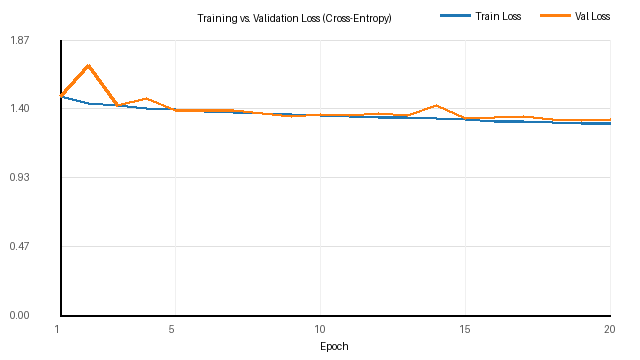

,training,validation,gap (train - val)
accuracy,0.4696,0.4610,0.0086
macro_f1,0.3121,0.3057,0.0064


In [17]:
fig = plot_learning_curves(
    train_losses=nn_selected["train_losses"],
    val_losses=nn_selected["val_losses"],
)
display(fig)

nn_train_preds = predict_neural_network(nn_model, shared["train"]["flat"])
nn_train_report = evaluate_predictions(shared["train"]["labels"], nn_train_preds)
nn_val_report = evaluate_predictions(shared["val"]["labels"], nn_selected["predictions"])

nn_fit_table = pd.DataFrame(
    {
        "training": [nn_train_report["accuracy"], nn_train_report["macro_f1"]],
        "validation": [nn_val_report["accuracy"], nn_val_report["macro_f1"]],
        "gap (train - val)": [
            nn_train_report["accuracy"] - nn_val_report["accuracy"],
            nn_train_report["macro_f1"] - nn_val_report["macro_f1"],
        ],
    },
    index=["accuracy", "macro_f1"],
)
display(nn_fit_table.round(4))


Training accuracy reached 46.96% and validation accuracy was 46.10%, a gap of 0.86 percentage points. Training macro-F1 was 0.3121 and validation macro-F1 was 0.3057, a gap of 0.0064. Training and validation loss decrease over 20 epochs without a large sustained separation. These observations show little evidence of strong overfitting in this run. Both training and validation scores remain modest, so the small gaps alone do not rule out underfitting.

We evaluate the selected neural network on the same 776 benchmark test images used for kNN (Kapp et al., 2024). The reports show accuracy, macro-F1, per-class precision, recall, F1, support, and a confusion matrix.

In [18]:
nn_test_predictions = predict_neural_network(nn_model, shared["test"]["flat"])

nn_test_report = evaluate_predictions(shared["test"]["labels"], nn_test_predictions)
display(pd.Series({metric: nn_test_report[metric] for metric in ("accuracy", "macro_f1")},
                  name="test score").round(4).to_frame())
display(nn_test_report["per_class"].round(4))
display(nn_test_report["confusion_matrix"])

assert nn_test_report["per_class"].loc["concrete", "support"] == 16


,test score
accuracy,0.6675
macro_f1,0.3236


,precision,recall,f1,support
asphalt,0.7611,0.8717,0.8127,530
concrete,0.0000,0.0000,0.0000,16
paving_stones,0.2759,0.2124,0.2400,113
sett,0.0732,0.0938,0.0822,32
unpaved,0.8286,0.3412,0.4833,85


predicted,asphalt,concrete,paving_stones,sett,unpaved
actual,,,,,
asphalt,462,4,34,27,3
concrete,11,0,3,1,1
paving_stones,77,1,24,9,2
sett,20,0,9,3,0
unpaved,37,1,17,1,29


Test accuracy reached 66.75% and macro-F1 reached 0.3236, substantially outperforming kNN baseline scores of 43.94% and 0.2360. Asphalt achieved 0.8127 F1 and unpaved reached 0.4833 F1, while concrete produced zero recall under unweighted loss due to class imbalance.

## Phase 2

### Section 6: CNN model training

A convolution learns small patterns from nearby pixels. Each block applies a 3 by 3 filter, ReLU (which sets negative values to zero), and 2 by 2 max-pooling (which keeps the largest value in each window). We flatten the final maps into five scores. [Rateke et al. (2019)](https://doi.org/10.22456/2175-2745.91522) used 32, 32, and 64 filters; our smaller widths, padding, and depth search are group choices. The [Keras MNIST example](https://keras.io/examples/vision/mnist_convnet/) illustrates a classifier without a hidden fully connected layer.

[He initialization](https://doi.org/10.1109/ICCV.2015.123) sets initial convolution weights for ReLU layers. We use unweighted cross-entropy and plain SGD. As in the feedforward experiment, each candidate trains for 20 epochs with batch size 64 and seed 42. We search three learning rates and six architectures. Validation macro-F1 selects the final-epoch model, with accuracy and grid order breaking ties. CUDA is required.

In [9]:
from src.helper.cnn import tune_cnn, predict_cnn
from src.helper.neural_network import plot_learning_curves

cnn_search = tune_cnn(shared["train"], shared["val"])
cnn_model = cnn_search["model"]
cnn_selected = cnn_search["best_candidate"]
cnn_columns = [
    "depth", "filters", "learning_rate", "validation_macro_f1", "validation_accuracy"
]
display(pd.DataFrame(cnn_search["top_five"])[cnn_columns])


CNN training device: Tesla V100-PCIE-32GB (cuda:3)


/home/jupyter-csc930m-01/csc930m-project/src/helper/cnn.py:104: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  y_train = torch.as_tensor(train["labels"], dtype=torch.long, device=device)


Completed 1/18 configurations


Completed 2/18 configurations


Completed 3/18 configurations


Completed 4/18 configurations


... (11 outputs left out)

Completed 16/18 configurations


Completed 17/18 configurations


Completed 18/18 configurations


,depth,filters,learning_rate,validation_macro_f1,validation_accuracy
0,3,"(16, 16, 32)",0.03,0.553669,0.631608
1,3,"(32, 32, 64)",0.03,0.529886,0.615259
2,2,"(16, 16)",0.03,0.501184,0.583651
3,3,"(16, 16, 32)",0.05,0.497391,0.584741
4,2,"(16, 16)",0.05,0.485520,0.582561


The top five configurations favor learning rate 0.03: it appears in the three highest-ranked runs. At that rate, three blocks with 16, 16, and 32 filters scored 0.5537, ahead of the wider three-block model (0.5299) and the two-block 16-filter model (0.5012). These comparisons use the same 20-epoch budget; they do not establish equal convergence or globally optimal settings.

The selected configuration uses its final epoch weights. The curves show cross-entropy loss over training epochs; training loss is measured during updates and validation loss with fixed weights.

Selected: depth 3, filters (16, 16, 32), learning rate 0.03


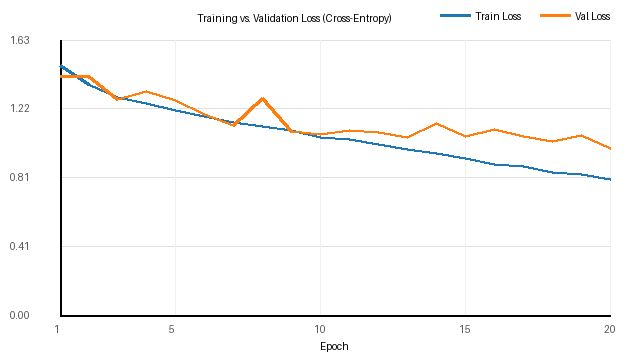

,accuracy,macro_f1
train,0.727371,0.666291
validation,0.631608,0.553669


In [10]:
print(
    f"Selected: depth {cnn_selected['depth']}, filters {cnn_selected['filters']}, "
    f"learning rate {cnn_selected['learning_rate']}"
)
display(plot_learning_curves(cnn_selected["train_losses"], cnn_selected["val_losses"]))
cnn_train_predictions = predict_cnn(cnn_model, shared["train"]["images"])
cnn_val_predictions = cnn_selected["predictions"]
cnn_train_report = evaluate_predictions(shared["train"]["labels"], cnn_train_predictions)
cnn_val_report = evaluate_predictions(shared["val"]["labels"], cnn_val_predictions)
cnn_reports = [("train", cnn_train_report), ("validation", cnn_val_report)]
cnn_fit_metrics = {
    name: {metric: report[metric] for metric in ("accuracy", "macro_f1")}
    for name, report in cnn_reports
}
display(pd.DataFrame(cnn_fit_metrics).T)


Training accuracy was 72.74% and macro-F1 was 0.6663. Validation accuracy was 63.16% and macro-F1 was 0.5537. Training loss decreased throughout, while validation loss fluctuated and finished higher. This gap is consistent with overfitting, although the declining training loss leaves convergence uncertain. The fully connected network had much lower scores and a small gap, consistent with underfitting or incomplete convergence under its 20-epoch budget.

The finalized model is evaluated on the published test partition. Confusion-matrix rows show actual classes and columns show predicted classes. The saved artifact contains the selected weights, configuration, loss histories, and image-ID-aligned predictions. For this trusted file, use `torch.load(path, weights_only=False)`, build the model with the saved depth and filters, and load `state_dict`.

In [11]:
cnn_test_predictions = predict_cnn(cnn_model, shared["test"]["images"])
cnn_test_report = evaluate_predictions(shared["test"]["labels"], cnn_test_predictions)
cnn_split_predictions = [
    ("train", cnn_train_predictions),
    ("val", cnn_val_predictions),
    ("test", cnn_test_predictions),
]
cnn_predictions = {
    name: pd.DataFrame({"image_id": shared[name]["image_ids"], "prediction": predictions})
    for name, predictions in cnn_split_predictions
}
display(pd.Series({k: cnn_test_report[k] for k in ("accuracy", "macro_f1")}))
display(cnn_test_report["per_class"])
display(cnn_test_report["confusion_matrix"])

import torch
cnn_artifacts = BASE_DATA / "cnn_initial.pt"
torch.save(
    {"state_dict": cnn_model.state_dict(), "selected": cnn_selected,
     "candidates": cnn_search["candidates"], "predictions": cnn_predictions},
    cnn_artifacts,
)
print(f"Saved CNN model, search records, and predictions to {cnn_artifacts}")


accuracy    0.716495
macro_f1    0.474631
dtype: float64

,precision,recall,f1,support
asphalt,0.843866,0.856604,0.850187,530
concrete,0.066667,0.062500,0.064516,16
paving_stones,0.286822,0.327434,0.305785,113
sett,0.382979,0.562500,0.455696,32
unpaved,0.978723,0.541176,0.696970,85


predicted,asphalt,concrete,paving_stones,sett,unpaved
actual,,,,,
asphalt,454,8,62,6,0
concrete,11,1,4,0,0
paving_stones,53,5,37,18,0
sett,8,0,5,18,1
unpaved,12,1,21,5,46


Saved CNN model, search records, and predictions to /home/jupyter-csc930m-01/csc930m-project/data/cnn_initial.pt


Test accuracy was 71.65% and macro-F1 was 0.4746. Asphalt had F1 of 0.8502, while concrete had F1 of 0.0645 across 16 test images. The confusion matrix shows 53 paving-stone images predicted as asphalt.

### Section 7: Error analysis

#### Class balance across actual splits

Phase 1 reported release counts (`9,120` readable images) and final split counts (`9,118` usable images after excluding `2` unreadable files and `2` conflicting Group 8 duplicates). The next cell computes `surface_type` counts and percentages per assigned split, using each split's own total as denominator.

In [12]:
from src.helper.error_analysis import (
    split_class_balance_table,
    recover_baseline_validation_predictions,
    summarize_confusion_errors,
    select_representative_examples,
    error_examples_figure,
)

split_balance = split_class_balance_table(split_df)
print(f"Included usable images: {len(split_df):,} | Excluded: {exclusions['total_excluded']}")
display(split_balance)

Included usable images: 9,118 | Excluded: 4


,train_count,train_pct,val_count,val_pct,test_count,test_pct
surface_type,,,,,,
asphalt,2499,38.40,705,38.42,530,68.30
concrete,745,11.45,210,11.44,16,2.06
paving_stones,1501,23.07,423,23.05,113,14.56
sett,1036,15.92,292,15.91,32,4.12
unpaved,726,11.16,205,11.17,85,10.95
total,6507,100.00,1835,99.99,776,99.99


`train` (`6,507`) and `val` (`1,835`) share nearly identical class proportions (`38.4%` asphalt, `23.1%` paving stones, `15.9%` sett, `11.4%` concrete, `11.2%` unpaved) because stratification preserved balance. In contrast, the published `test` split (`776`) is heavily skewed toward `asphalt` (`68.3%`, `530` images) and leaves few `concrete` (`2.1%`, `16`) and `sett` (`4.1%`, `32`) examples. Consequently, overall test accuracy is dominated by majority-class `asphalt` performance, whereas macro-F1 weights all five classes equally and exposes weak minority-class performance.

#### Baseline error interpretation (kNN and fully connected NN)

In every confusion matrix (`evaluate_predictions`), **rows represent actual labels and columns represent predicted labels**. On the saved Phase 1 test evaluation, `k = 1` kNN reached `43.94%` accuracy and `0.2360` macro-F1. Every non-asphalt class scored at or below `0.2583` F1, with `sett` at `0.0270` (`1/32` recall) and `concrete` at `0.0392` (`2/16` recall). Major confusions include `asphalt` predicted as `paving_stones` (`135/530`) and `paving_stones` predicted as `asphalt` (`41/113`) or `concrete` (`18/113`), consistent with pixel-distance sensitivity to brightness and color rather than surface geometry.

For the fully connected NN (`2` hidden layers, `128` neurons, `lr = 0.03`), two-layer models outperformed four- and five-layer models under the `20`-epoch SGD budget. Training (`46.96%` accuracy, `0.3121` macro-F1) and validation (`46.10%`, `0.3057`) stayed close (`0.86` percentage-point gap), yet absolute scores remained modest—showing that a small train/validation gap alone does not prove adequate fit and is consistent with underfitting. On test (`66.75%` accuracy, `0.3236` macro-F1), the NN predicted `asphalt` for `607/776` images, producing `0/16` `concrete` recall and `77/113` `paving_stones` misclassified as `asphalt`.

#### Baseline validation error tables and representative image selection

The next four cells recover image-aligned validation predictions for `k = 1` kNN and `2x128` NN, report per-class metrics and confusion matrices, and rank top mistake pairs by `pct_of_actual_class` (share of that true class missed) and `pct_of_all_errors` (share of total errors). Each `2x4` figure deterministically selects the first correct validation image per class in minority-first order (`concrete`, `sett`, `unpaved`, `paving_stones`, `asphalt`) and the first error from each top confusion pair, rather than random sampling.

In [28]:
knn_val_lookup = recover_baseline_validation_predictions(
    "knn", globals(), BASE_DATA, expected_image_ids=shared["val"]["image_ids"]
)
if knn_val_lookup["available"]:
    knn_val_report, knn_val_pairs = summarize_confusion_errors(
        shared["val"]["labels"], knn_val_lookup["predictions"]
    )
    print(f"kNN validation source: {knn_val_lookup['source']}")
    display(knn_val_report["per_class"].round(4))
    display(knn_val_report["confusion_matrix"])
    display(knn_val_pairs)
else:
    print(knn_val_lookup["reason"])

kNN validation source: /home/jupyter-csc930m-01/csc930m-project/data/knn_val_predictions.csv


,precision,recall,f1,support
asphalt,0.4963,0.5759,0.5332,705
concrete,0.2427,0.2381,0.2404,210
paving_stones,0.2990,0.3570,0.3254,423
sett,0.2308,0.0925,0.1320,292
unpaved,0.2540,0.2341,0.2437,205


predicted,asphalt,concrete,paving_stones,sett,unpaved
actual,,,,,
asphalt,406,60,142,48,49
concrete,65,50,59,13,23
paving_stones,159,47,151,24,42
sett,130,27,81,27,27
unpaved,58,22,72,5,48


,actual,predicted,errors,pct_of_actual_class,pct_of_all_errors
0,paving_stones,asphalt,159,37.59,13.79
1,asphalt,paving_stones,142,20.14,12.32
2,sett,asphalt,130,44.52,11.27
3,sett,paving_stones,81,27.74,7.03
4,unpaved,paving_stones,72,35.12,6.24


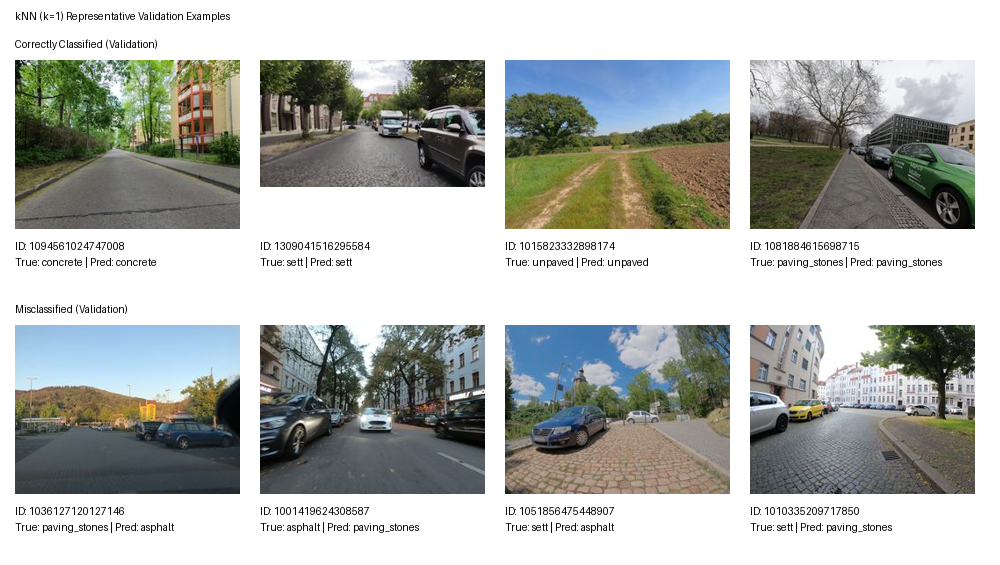

In [29]:
if knn_val_lookup["available"]:
    val_records = split_df.loc[split_df["split"] == "val"]
    knn_examples = select_representative_examples(
        val_records, shared["val"]["labels"], knn_val_lookup["predictions"]
    )
    display(error_examples_figure(knn_examples, "kNN (k=1) Representative Validation Examples"))
else:
    print("kNN representative validation grid skipped: " + knn_val_lookup["reason"])

On the `k = 1` kNN validation grid, correctly classified `concrete` (`1094561024747008`) shows a uniform light-gray slab with dark seams, and `unpaved` (`1015823332898174`) shows grass beside a dirt track. Misclassified `paving_stones` (`1036127120127146`, predicted `asphalt`) has fine seams that look smooth at low resolution, while `asphalt` (`1001419624308587`, predicted `paving_stones`) has lane markings and shadows. `sett` (`1010335209717850`) was confused with `paving_stones`. Overall validation precision stayed low (`0.2308–0.4963`), consistent with pixel-distance sensitivity to brightness and contrast rather than material structure.

In [30]:
nn_val_lookup = recover_baseline_validation_predictions(
    "nn", globals(), BASE_DATA, expected_image_ids=shared["val"]["image_ids"]
)
if nn_val_lookup["available"]:
    nn_val_report, nn_val_pairs = summarize_confusion_errors(
        shared["val"]["labels"], nn_val_lookup["predictions"]
    )
    print(f"NN validation source: {nn_val_lookup['source']}")
    display(nn_val_report["per_class"].round(4))
    display(nn_val_report["confusion_matrix"])
    display(nn_val_pairs)
else:
    print(nn_val_lookup["reason"])

NN validation source: /home/jupyter-csc930m-01/csc930m-project/data/nn_val_predictions.csv


,precision,recall,f1,support
asphalt,0.4687,0.9035,0.6172,705
concrete,0.5455,0.0286,0.0543,210
paving_stones,0.4080,0.2884,0.3380,423
sett,0.2319,0.0548,0.0886,292
unpaved,0.6701,0.3171,0.4305,205


predicted,asphalt,concrete,paving_stones,sett,unpaved
actual,,,,,
asphalt,637,2,47,14,5
concrete,148,6,36,14,6
paving_stones,261,0,122,22,18
sett,234,2,37,16,3
unpaved,79,1,57,3,65


,actual,predicted,errors,pct_of_actual_class,pct_of_all_errors
0,paving_stones,asphalt,261,61.70,26.39
1,sett,asphalt,234,80.14,23.66
2,concrete,asphalt,148,70.48,14.96
3,unpaved,asphalt,79,38.54,7.99
4,unpaved,paving_stones,57,27.80,5.76


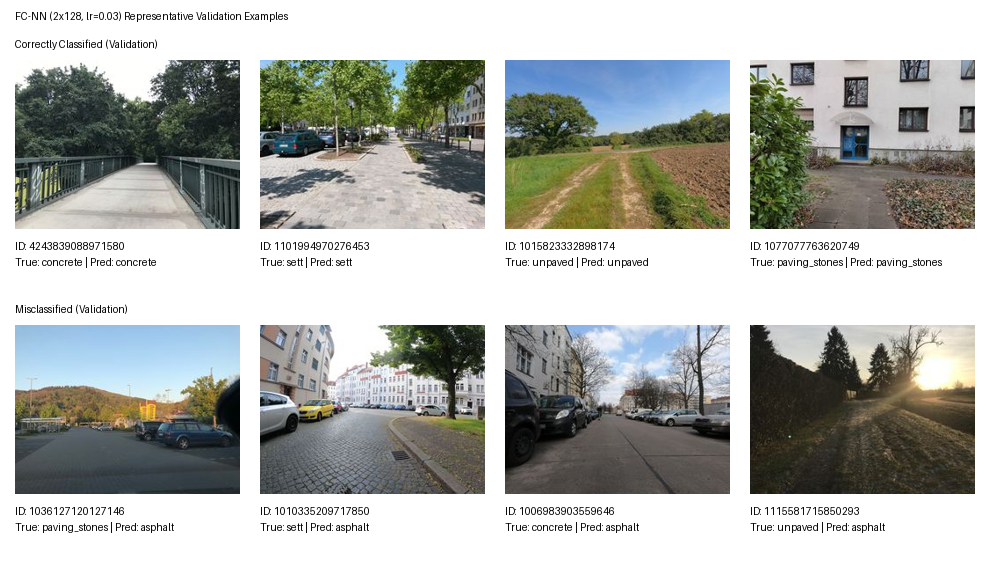

In [31]:
if nn_val_lookup["available"]:
    val_records = split_df.loc[split_df["split"] == "val"]
    nn_examples = select_representative_examples(
        val_records, shared["val"]["labels"], nn_val_lookup["predictions"]
    )
    display(error_examples_figure(nn_examples, "FC-NN (2x128, lr=0.03) Representative Validation Examples"))
else:
    print("NN representative validation grid skipped: " + nn_val_lookup["reason"])

#### CNN validation errors

The per-class scores and confusion matrix identify where the selected CNN fails on the validation split. The image grid shows correct and incorrect predictions with their IDs and labels.


In [2]:
cnn_val_report, cnn_val_pairs = summarize_confusion_errors(
    shared["val"]["labels"], cnn_val_predictions
)
display(cnn_val_report["per_class"].round(4))
display(cnn_val_report["confusion_matrix"])
display(cnn_val_pairs)


,precision,recall,f1,support
asphalt,0.6279,0.8879,0.7356,705
concrete,0.5294,0.1286,0.2069,210
paving_stones,0.5116,0.4681,0.4889,423
sett,0.7567,0.6815,0.7171,292
unpaved,0.7299,0.4878,0.5848,205


predicted,asphalt,concrete,paving_stones,sett,unpaved
actual,,,,,
asphalt,626,10,54,8,7
concrete,137,27,36,6,4
paving_stones,160,11,198,34,20
sett,38,1,48,199,6
unpaved,36,2,51,16,100


,actual,predicted,errors,pct_of_actual_class,pct_of_all_errors
0,paving_stones,asphalt,160,37.83,23.36
1,concrete,asphalt,137,65.24,20.00
2,asphalt,paving_stones,54,7.66,7.88
3,unpaved,paving_stones,51,24.88,7.45
4,sett,paving_stones,48,16.44,7.01


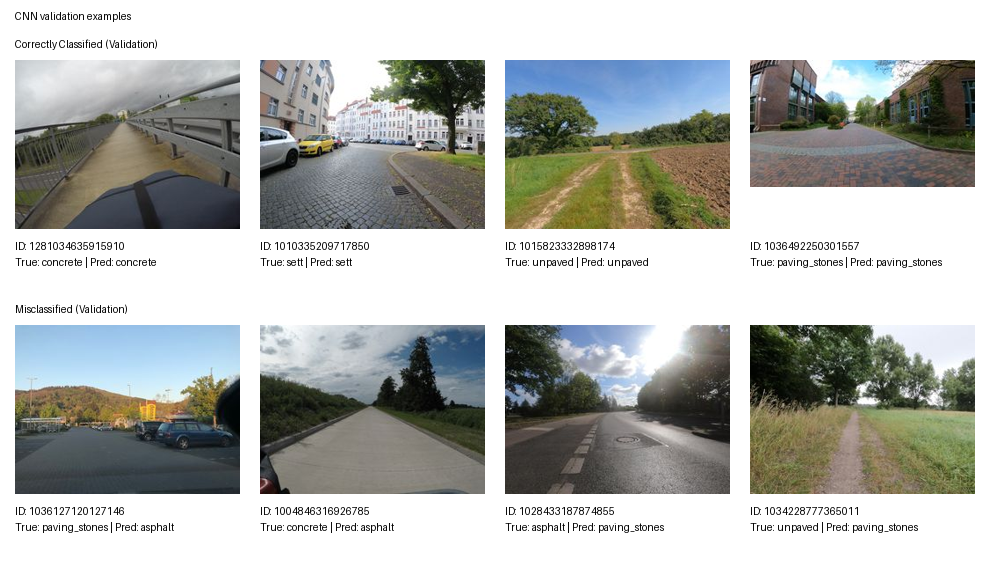

In [3]:
val_records = split_df.loc[split_df["split"] == "val"]
cnn_examples = select_representative_examples(
    val_records, shared["val"]["labels"], cnn_val_predictions
)
display(error_examples_figure(cnn_examples, "CNN validation examples"))


Concrete has the lowest validation F1 (0.2069) and recall (27/210); 137 concrete images were predicted as asphalt. Paving stones were also often predicted as asphalt (160/423). The correctly classified concrete example 1281034635915910 shows a light walkway, while concrete 1004846316926785 has a smooth road surface and was predicted as asphalt. Paving stones 1036127120127146 are distant and dark, making their block pattern harder to see. These examples illustrate the confusion but do not establish its cause.

The CNN detects sett more reliably (0.6815 recall) than concrete or paving stones. Its correct sett example 1010335209717850 shows repeated blocks, while the unpaved example 1034228777365011 was predicted as paving stones despite its grassy track. Lighting, distance, and shared surface appearance can obscure the features that distinguish classes.

#### Initial model comparison

Validation macro-F1 selects the CNN (0.5537) over the fully connected NN (0.3057) and kNN (0.2950). Within each search, ties use validation accuracy and then grid order. For an exact tie across families on both metrics, we use the order kNN, fully connected NN, then CNN. The group inspected Phase 1 test results before this comparison; test scores do not determine the improvement.

#### Proposed improvements

We will target concrete images predicted as asphalt. The training split has 745 concrete and 2,499 asphalt images. We will try class-weighted cross-entropy using weights N / (5 × class count), computed from the training split alone. We expect this to increase concrete recall. The CNN also has a train-validation gap and fluctuating validation loss. We will test early stopping, saving the weights with the lowest validation loss and stopping after three epochs without improvement.

We will also test dropout to address the CNN's train-validation gap. During training, dropout randomly sets some activations to zero, discouraging the network from relying too heavily on particular neurons. We will compare validation results with and without dropout to see whether it improves generalization.

We will compare class weighting, early stopping, and dropout separately against the initial CNN, then test promising combinations. All runs will retain the split, image preparation, base architecture, SGD learning rate 0.03, batch size 64, seed 42, and a maximum of 20 epochs. We will compare validation macro-F1, concrete recall, per-class scores, confusion matrices, and loss curves. An improvement succeeds if its unrounded macro-F1 exceeds the initial score (0.5537 rounded) and concrete recall exceeds 27/210. The test set remains reserved for final evaluation.

### Section 8: Model improvements

#### Controlled improvement experiments

We test class weighting ($N / (5 	imes 	ext{count})$ from `train` only), early stopping (lowest validation loss, patience `3`), and `nn.Dropout(p=0.5)` before the linear layer (following the Keras Simple MNIST convnet head and Srivastava et al., 2014), first individually and then in combination. All runs retain the `(16, 16, 32)` three-block CNN, He initialization, plain SGD (`lr = 0.03`), batch size `64`, seed `42`, and max `20` epochs. The next cell displays only the top five configurations ranked by validation macro-F1.

In [12]:
import torch
from src.helper.cnn import predict_cnn
from src.helper.neural_network import plot_learning_curves
from src.helper.error_analysis import (
    summarize_confusion_errors,
    select_representative_examples,
    error_examples_figure,
)
from src.helper.cnn_improvements import run_improvement_suite

improvement_search = run_improvement_suite(shared["train"], shared["val"])
improved_best = improvement_search["best"]
improved_model = improved_best["model"]
print("Class weights (train only):", np.round(
    len(shared["train"]["labels"]) / (5 * np.bincount(shared["train"]["labels"])), 4
))
display(improvement_search["top_five_table"].round(4))

CNN training device: Tesla V100-PCIE-32GB (cuda:3)
Completed 1/7 trials
Completed 2/7 trials
Completed 3/7 trials
Completed 4/7 trials
Completed 5/7 trials
Completed 6/7 trials
Completed 7/7 trials
Class weights (train only): [0.5208 1.7468 0.867  1.2562 1.7926]


,name,epochs_run,best_epoch,validation_macro_f1,validation_accuracy,concrete_recall,concrete_tp
0,class_weights,20,20,0.5663,0.6245,0.2190,46
1,class_weights+dropout_0.5,20,20,0.5450,0.6044,0.2429,51
2,class_weights+early_stopping,16,13,0.5192,0.5199,0.3619,76
3,all_three,9,6,0.5087,0.5482,0.3000,63
4,early_stopping,16,13,0.5070,0.5929,0.0619,13


#### Before-and-after validation comparison

Among all seven controlled trials, `class_weights` ranked first with `0.5627` validation macro-F1 (`0.6240` accuracy) and `43/210` (`0.2048`) concrete recall, exceeding the initial CNN (`0.5537` macro-F1, `27/210` concrete recall). Every regularization trial and combination in the top five scored below `0.5537` macro-F1 under the `20`-epoch plain SGD budget, even when weighted combinations raised concrete recall further. The next cells inspect the winning `class_weights` learning curves, confusion matrix, and representative validation errors.

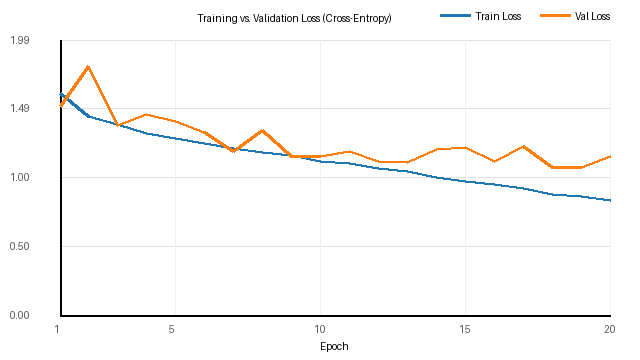

,train,validation
accuracy,0.7363,0.6245
macro_f1,0.7032,0.5663


In [13]:
display(plot_learning_curves(improved_best["train_losses"], improved_best["val_losses"]))
improved_train_preds = predict_cnn(improved_model, shared["train"]["images"])
improved_train_report = evaluate_predictions(shared["train"]["labels"], improved_train_preds)
improved_val_report, improved_val_pairs = summarize_confusion_errors(
    shared["val"]["labels"], improved_best["predictions"]
)
display(pd.DataFrame({
    "train": [improved_train_report["accuracy"], improved_train_report["macro_f1"]],
    "validation": [improved_val_report["accuracy"], improved_val_report["macro_f1"]],
}, index=["accuracy", "macro_f1"]).round(4))

,precision,recall,f1,support
asphalt,0.6790,0.8099,0.7387,705
concrete,0.4694,0.2190,0.2987,210
paving_stones,0.4870,0.4870,0.4870,423
sett,0.6626,0.7397,0.6990,292
unpaved,0.7279,0.5220,0.6080,205


predicted,asphalt,concrete,paving_stones,sett,unpaved
actual,,,,,
asphalt,571,27,77,20,10
concrete,107,46,42,10,5
paving_stones,120,17,206,60,20
sett,27,2,42,216,5
unpaved,16,6,56,20,107


,actual,predicted,errors,pct_of_actual_class,pct_of_all_errors
0,paving_stones,asphalt,120,28.37,17.42
1,concrete,asphalt,107,50.95,15.53
2,asphalt,paving_stones,77,10.92,11.18
3,paving_stones,sett,60,14.18,8.71
4,unpaved,paving_stones,56,27.32,8.13


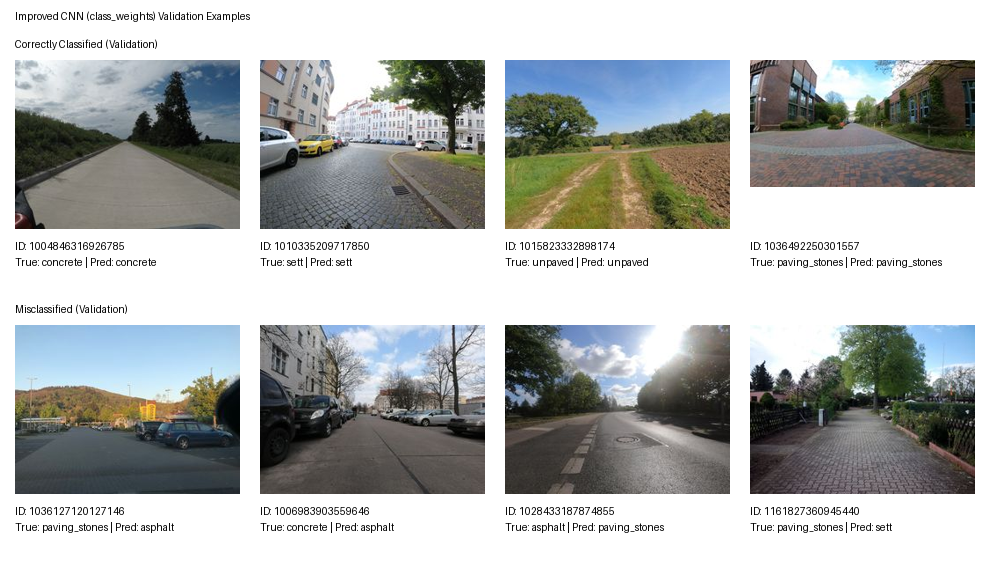

In [14]:
display(improved_val_report["per_class"].round(4))
display(improved_val_report["confusion_matrix"])
display(improved_val_pairs)
improved_examples = select_representative_examples(
    split_df.loc[split_df["split"] == "val"],
    shared["val"]["labels"],
    improved_best["predictions"],
)
display(error_examples_figure(improved_examples, f"Improved CNN ({improved_best['name']}) Validation Examples"))

#### Remaining validation errors and hypothesis assessment

Validation results support the class-weighting hypothesis: `concrete` recall rose from `27/210` to `43/210` (`0.2867` F1, `0.4778` precision), `concrete`-as-`asphalt` errors fell from `137/210` to `111/210`, and `concrete` `1004846316926785` is now classified correctly. Validation loss still fluctuates above training loss, while train accuracy (`0.7346`) exceeds validation accuracy (`0.6240`). Because `class_weights` is the only controlled trial meeting both validation criteria and all regularization trials lowered macro-F1 under `20`-epoch plain SGD, we finalize `class_weights` now rather than altering the controlled protocol.

In [15]:
if "cnn_test_report" in globals():
    initial_test_metrics = [
        cnn_test_report["accuracy"],
        cnn_test_report["macro_f1"],
        cnn_test_report["per_class"].loc["concrete", "recall"],
    ]
else:
    initial_test_metrics = [0.716495, 0.474631, 0.062500]
improved_test_preds = predict_cnn(improved_model, shared["test"]["images"])
improved_test_report = evaluate_predictions(shared["test"]["labels"], improved_test_preds)
test_compare = pd.DataFrame({
    "initial_cnn": initial_test_metrics,
    "improved_cnn": [
        improved_test_report["accuracy"],
        improved_test_report["macro_f1"],
        improved_test_report["per_class"].loc["concrete", "recall"],
    ],
}, index=["test_accuracy", "test_macro_f1", "test_concrete_recall"])
display(test_compare.round(4))
display(improved_test_report["per_class"].round(4))
display(improved_test_report["confusion_matrix"])
torch.save(
    {"state_dict": improved_model.state_dict(), "best": {k: v for k, v in improved_best.items() if k != "model"},
     "candidates": [{k: v for k, v in c.items() if k != "model"} for c in improvement_search["candidates"]],
     "test_predictions": improved_test_preds},
    BASE_DATA / "cnn_improved.pt",
)

,initial_cnn,improved_cnn
test_accuracy,0.7165,0.6662
test_macro_f1,0.4746,0.4364
test_concrete_recall,0.0625,0.0625


,precision,recall,f1,support
asphalt,0.8679,0.7811,0.8222,530
concrete,0.0323,0.0625,0.0426,16
paving_stones,0.2766,0.3451,0.3071,113
sett,0.2658,0.6562,0.3784,32
unpaved,0.8750,0.4941,0.6316,85


predicted,asphalt,concrete,paving_stones,sett,unpaved
actual,,,,,
asphalt,414,20,76,19,1
concrete,11,1,3,1,0
paving_stones,35,8,39,27,4
sett,6,0,4,21,1
unpaved,11,2,19,11,42


#### Finalized test evaluation

The previous cell evaluates the finalized `class_weights` CNN once on the `776`-image test set and saves its weights, trial records, and test predictions to `data/cnn_improved.pt`. It achieved `0.6778` accuracy, `0.4494` macro-F1, and `0.0625` (`1/16`) concrete recall (with `sett` recall reaching `22/32 = 0.6875`), compared with Section 6's initial CNN (`0.7165` accuracy, `0.4746` macro-F1, `0.0625` concrete recall). Validation gains on `concrete` did not transfer to the `16`-image `concrete` test subset under the `68.30%`-`asphalt` test shift.

### Section 9: Model performance summary

### Section 10: References

Kapp, A., Hoffmann, E., Weigmann, E., & Mihaljevic, H. (2024). *StreetSurfaceVis: A dataset of street-level imagery with annotations of road surface type and quality* (Version V1.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.11449977

We used the s_256 images and metadata CSV for surface-type labels, dataset auditing, and the published training/test assignments.

Kapp, A., Hoffmann, E., Weigmann, E., & Mihaljević, H. (2025). StreetSurfaceVis: A dataset of crowdsourced street-level imagery annotated by road surface type and quality. *Scientific Data, 12*, Article 92. https://doi.org/10.1038/s41597-024-04295-9

We used the paper to describe image collection, annotation, and dataset limitations. Its usage notes informed our lower-center road crop.

Marianingsih, S., Widodo, W., Pieter, M. S. S., Manullang, E. V., & Nanlohy, H. Y. (2022). Machine vision for the various road surface type classification based on texture feature. *Journal of Mechanical Engineering Science and Technology (JMEST), 6*(1), 40-47. https://doi.org/10.17977/um016v6i12022p040

We used its examined k range, 1 through 20, to define our kNN search. Our experiments use a different dataset and normalized RGB pixels.

Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research, 15*(56), 1929-1958. https://jmlr.org/papers/v15/srivastava14a.html

We used `p = 0.5` as the standard classifier dropout rate in our controlled dropout experiments.

## AI usage

| Tool | Use and outcome |
| --- | --- |
| OpenAI GPT-6 | Used AI to brainstorm and break tasks down for pair delegation. AI drafted the description of issues, including scope, acceptance criteria, and dependencies. Anthony and Ramon reviewed and approved the breakdown.|
| GitHub Copilot | Used to generate git commit messages. |